# 05 - Multiclass Intrusion Detection

**Objective:** Train and evaluate a multiclass classifier that identifies the specific traffic class.

**Models:** Random Forest and XGBoost

**Evaluation:** Accuracy, balanced accuracy, macro-F1, weighted-F1, per-class precision and recall, and confusion matrix.

**Data integrity:** Reuse the saved dataset and split indices from the earlier notebooks. Do not create a new random split.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

FINAL_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "cic_ids2017_cleaned_deduplicated.parquet"
)

SPLITS_DIR = PROJECT_ROOT / "data" / "splits"
MODELS_DIR = PROJECT_ROOT / "models" / "multiclass"
METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"

for directory in [
    MODELS_DIR,
    METRICS_DIR,
    FIGURES_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

assert FINAL_DATA_PATH.exists(), f"Dataset not found: {FINAL_DATA_PATH}"
assert (SPLITS_DIR / "train_indices.csv").exists()
assert (SPLITS_DIR / "validation_indices.csv").exists()
assert (SPLITS_DIR / "test_indices.csv").exists()

print("Project paths verified.")
print("Dataset:", FINAL_DATA_PATH)
print("Splits:", SPLITS_DIR)

Project paths verified.
Dataset: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\data\processed\cic_ids2017_cleaned_deduplicated.parquet
Splits: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\data\splits


In [2]:
# Load the saved split indices
train_indices = pd.read_csv(
    SPLITS_DIR / "train_indices.csv"
).squeeze("columns").to_numpy()

val_indices = pd.read_csv(
    SPLITS_DIR / "validation_indices.csv"
).squeeze("columns").to_numpy()

test_indices = pd.read_csv(
    SPLITS_DIR / "test_indices.csv"
).squeeze("columns").to_numpy()

print("SPLIT INDEX VALIDATION")
print("=" * 50)

print(f"Training indices:   {len(train_indices):,}")
print(f"Validation indices: {len(val_indices):,}")
print(f"Test indices:       {len(test_indices):,}")

# Check index uniqueness
assert len(np.unique(train_indices)) == len(train_indices)
assert len(np.unique(val_indices)) == len(val_indices)
assert len(np.unique(test_indices)) == len(test_indices)

# Check that the splits do not overlap
train_set = set(train_indices)
val_set = set(val_indices)
test_set = set(test_indices)

assert train_set.isdisjoint(val_set), "Train/validation overlap!"
assert train_set.isdisjoint(test_set), "Train/test overlap!"
assert val_set.isdisjoint(test_set), "Validation/test overlap!"

# Check total row count
total_split_rows = (
    len(train_indices)
    + len(val_indices)
    + len(test_indices)
)

print(f"\nTotal rows across splits: {total_split_rows:,}")
print("Split overlap check: PASS")

SPLIT INDEX VALIDATION
Training indices:   2,016,638
Validation indices: 252,080
Test indices:       252,080

Total rows across splits: 2,520,798
Split overlap check: PASS


In [3]:
# Inspect the index ranges
print("INDEX RANGE VALIDATION")
print("=" * 50)

print(
    "Training range:",
    int(train_indices.min()),
    "to",
    int(train_indices.max())
)

print(
    "Validation range:",
    int(val_indices.min()),
    "to",
    int(val_indices.max())
)

print(
    "Test range:",
    int(test_indices.min()),
    "to",
    int(test_indices.max())
)

# The expected dataset has 2,520,798 rows.
expected_rows = 2_520_798

all_indices = np.concatenate([
    train_indices,
    val_indices,
    test_indices
])

assert all_indices.min() >= 0, "Negative index found."
assert all_indices.max() < expected_rows, "Index exceeds dataset size."

# Every positional row should appear exactly once.
assert len(np.unique(all_indices)) == expected_rows

print("\nIndex range and complete coverage: PASS")

INDEX RANGE VALIDATION
Training range: 0 to 2520797
Validation range: 9 to 2520793
Test range: 27 to 2520794

Index range and complete coverage: PASS


In [4]:
# Load the saved multiclass label mapping
LABEL_MAPPING_PATH = SPLITS_DIR / "label_mapping.json"

assert LABEL_MAPPING_PATH.exists(), (
    f"Label mapping not found: {LABEL_MAPPING_PATH}"
)

with open(LABEL_MAPPING_PATH, "r", encoding="utf-8") as f:
    saved_mapping = json.load(f)

print("SAVED LABEL MAPPING")
print("=" * 50)
print(json.dumps(saved_mapping, indent=4))

SAVED LABEL MAPPING
{
    "binary": {
        "0": "BENIGN",
        "1": "ATTACK"
    },
    "multiclass": {
        "0": "BENIGN",
        "1": "Bot",
        "2": "DDoS",
        "3": "DoS GoldenEye",
        "4": "DoS Hulk",
        "5": "DoS Slowhttptest",
        "6": "DoS slowloris",
        "7": "FTP-Patator",
        "8": "Heartbleed",
        "9": "Infiltration",
        "10": "PortScan",
        "11": "SSH-Patator",
        "12": "Web Attack - Brute Force",
        "13": "Web Attack - Sql Injection",
        "14": "Web Attack - XSS"
    }
}


In [5]:
# Extract the multiclass mapping
id_to_label = {
    int(class_id): label
    for class_id, label in saved_mapping["multiclass"].items()
}

label_to_id = {
    label: class_id
    for class_id, label in id_to_label.items()
}

print("MULTICLASS LABEL VALIDATION")
print("=" * 50)

for class_id in sorted(id_to_label):
    print(f"{class_id:2} -> {id_to_label[class_id]}")

# Validate class IDs and uniqueness
expected_class_ids = list(range(15))

assert sorted(id_to_label.keys()) == expected_class_ids
assert len(label_to_id) == 15
assert len(set(id_to_label.values())) == 15

print("\nNumber of classes:", len(id_to_label))
print("Class IDs are consecutive: PASS")
print("Class names are unique: PASS")

MULTICLASS LABEL VALIDATION
 0 -> BENIGN
 1 -> Bot
 2 -> DDoS
 3 -> DoS GoldenEye
 4 -> DoS Hulk
 5 -> DoS Slowhttptest
 6 -> DoS slowloris
 7 -> FTP-Patator
 8 -> Heartbleed
 9 -> Infiltration
10 -> PortScan
11 -> SSH-Patator
12 -> Web Attack - Brute Force
13 -> Web Attack - Sql Injection
14 -> Web Attack - XSS

Number of classes: 15
Class IDs are consecutive: PASS
Class names are unique: PASS


In [6]:
import pyarrow.parquet as pq

parquet_file = pq.ParquetFile(FINAL_DATA_PATH)

print("Parquet rows:", f"{parquet_file.metadata.num_rows:,}")
print("Parquet row groups:", parquet_file.num_row_groups)
print("Columns available:", len(parquet_file.schema.names))

Parquet rows: 2,520,798
Parquet row groups: 3
Columns available: 79


In [7]:
# Read only the labels from the Parquet dataset
labels_df = pd.read_parquet(
    FINAL_DATA_PATH,
    columns=["Label"]
)

assert len(labels_df) == parquet_file.metadata.num_rows

# Convert labels to integer class IDs
y_all = labels_df["Label"].map(label_to_id)

assert y_all.notna().all(), (
    "Some labels are missing from the saved multiclass mapping."
)

y_all = y_all.astype("int8").to_numpy()

# Check that indices are positional and valid
assert all_indices.min() >= 0
assert all_indices.max() < len(y_all)

# Compute class counts using the exact saved splits
distribution_rows = []

for split_name, indices in [
    ("Train", train_indices),
    ("Validation", val_indices),
    ("Test", test_indices),
]:
    counts = pd.Series(y_all[indices]).value_counts()

    for class_id, class_name in id_to_label.items():
        distribution_rows.append({
            "Class ID": class_id,
            "Label": class_name,
            "Split": split_name,
            "Count": int(counts.get(class_id, 0))
        })

distribution_df = pd.DataFrame(distribution_rows)

distribution_table = distribution_df.pivot(
    index=["Class ID", "Label"],
    columns="Split",
    values="Count"
).fillna(0).astype(int)

display(distribution_table)

print("\nTotal rows checked:", f"{len(y_all):,}")
print("Label-to-ID conversion: PASS")

,Split,Test,Train,Validation
Class ID,Label,,,
0,BENIGN,209506,1676045,209506
1,Bot,195,1558,195
2,DDoS,12801,102412,12801
3,DoS GoldenEye,1029,8228,1029
4,DoS Hulk,17285,138276,17285
5,DoS Slowhttptest,523,4182,523
6,DoS slowloris,538,4308,539
7,FTP-Patator,593,4745,593
8,Heartbleed,1,9,1



Total rows checked: 2,520,798
Label-to-ID conversion: PASS


In [8]:
# Prepare multiclass target arrays using the saved splits

y_train_multi = y_all[train_indices]
y_val_multi = y_all[val_indices]
y_test_multi = y_all[test_indices]

print("MULTICLASS TARGET SHAPES")
print("=" * 50)

print("Training:", y_train_multi.shape)
print("Validation:", y_val_multi.shape)
print("Test:", y_test_multi.shape)

print("\nUnique classes per split:")
print("Training:", len(np.unique(y_train_multi)))
print("Validation:", len(np.unique(y_val_multi)))
print("Test:", len(np.unique(y_test_multi)))

# Verify target alignment and class IDs
assert len(y_train_multi) == len(train_indices)
assert len(y_val_multi) == len(val_indices)
assert len(y_test_multi) == len(test_indices)

assert set(np.unique(y_train_multi)) == set(range(15))

print("\nMulticlass targets prepared: PASS")

MULTICLASS TARGET SHAPES
Training: (2016638,)
Validation: (252080,)
Test: (252080,)

Unique classes per split:
Training: 15
Validation: 15
Test: 15

Multiclass targets prepared: PASS


In [9]:
# Inspect feature columns from Parquet metadata
all_columns = parquet_file.schema.names

assert "Label" in all_columns

FEATURE_COLUMNS = [
    column for column in all_columns
    if column != "Label"
]

print("FEATURE VALIDATION")
print("=" * 50)
print("Total dataset columns:", len(all_columns))
print("Feature columns:", len(FEATURE_COLUMNS))
print("Label column excluded:", "Label" not in FEATURE_COLUMNS)

assert len(FEATURE_COLUMNS) == 78
assert len(set(FEATURE_COLUMNS)) == 78

print("\nFeature column validation: PASS")
print("\nFirst 10 features:")
for feature in FEATURE_COLUMNS[:10]:
    print("-", feature)

FEATURE VALIDATION
Total dataset columns: 79
Feature columns: 78
Label column excluded: True

Feature column validation: PASS

First 10 features:
- Destination Port
- Flow Duration
- Total Fwd Packets
- Total Backward Packets
- Total Length of Fwd Packets
- Total Length of Bwd Packets
- Fwd Packet Length Max
- Fwd Packet Length Min
- Fwd Packet Length Mean
- Fwd Packet Length Std


In [10]:

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

# Inspect the Parquet schema without loading the entire dataset
parquet_file = pq.ParquetFile(FINAL_DATA_PATH)
schema = parquet_file.schema_arrow

feature_schema = {
    field.name: str(field.type)
    for field in schema
    if field.name in FEATURE_COLUMNS
}

non_numeric_features = {
    name: dtype
    for name, dtype in feature_schema.items()
    if not (
        dtype.startswith(("int", "uint", "float", "double", "halffloat"))
    )
}

print("FEATURE SCHEMA VALIDATION")
print("=" * 55)
print("Expected features:", len(FEATURE_COLUMNS))
print("Features found in schema:", len(feature_schema))
print("Non-numeric features:", non_numeric_features)

assert len(feature_schema) == len(FEATURE_COLUMNS), (
    "Feature count does not match the Parquet schema."
)

assert not non_numeric_features, (
    "Some features are not numeric. Inspect them before training."
)

print("\nFeature schema validation: PASS")


FEATURE SCHEMA VALIDATION
Expected features: 78
Features found in schema: 78
Non-numeric features: {}

Feature schema validation: PASS


In [12]:

invalid_missing = 0
invalid_infinite = 0
rows_checked = 0

for group_index in range(parquet_file.num_row_groups):
    batch_df = parquet_file.read_row_group(
        group_index,
        columns=FEATURE_COLUMNS
    ).to_pandas()

    values = batch_df.to_numpy(dtype=np.float64, copy=False)

    invalid_missing += int(np.isnan(values).sum())
    invalid_infinite += int(np.isinf(values).sum())
    rows_checked += len(batch_df)

    print(
        f"Checked row group {group_index + 1}/"
        f"{parquet_file.num_row_groups}: "
        f"{len(batch_df):,} rows"
    )

    del batch_df, values

print("\nNUMERICAL VALIDATION")
print("=" * 55)
print("Rows checked:", f"{rows_checked:,}")
print("Missing feature values:", f"{invalid_missing:,}")
print("Infinite feature values:", f"{invalid_infinite:,}")

assert rows_checked == parquet_file.metadata.num_rows
assert invalid_missing == 0, "Missing feature values detected."
assert invalid_infinite == 0, "Infinite feature values detected."

print("\nNumerical validation: PASS")


Checked row group 1/3: 1,048,576 rows
Checked row group 2/3: 1,048,576 rows
Checked row group 3/3: 423,646 rows

NUMERICAL VALIDATION
Rows checked: 2,520,798
Missing feature values: 0
Infinite feature values: 0

Numerical validation: PASS


In [26]:

import os
import psutil

process = psutil.Process(os.getpid())
memory = psutil.virtual_memory()

print("SYSTEM MEMORY CHECK")
print("=" * 45)
print(f"Total RAM: {memory.total / (1024**3):.2f} GB")
print(f"Available RAM: {memory.available / (1024**3):.2f} GB")
print(f"RAM usage: {memory.percent}%")
print(
    f"Notebook process RAM: "
    f"{process.memory_info().rss / (1024**3):.2f} GB"
)


SYSTEM MEMORY CHECK
Total RAM: 7.37 GB
Available RAM: 1.60 GB
RAM usage: 78.3%
Notebook process RAM: 0.02 GB


In [28]:

import pandas as pd
from pathlib import Path

# Load the saved training indices
TRAIN_INDICES_PATH = SPLITS_DIR / "train_indices.csv"

assert TRAIN_INDICES_PATH.exists(), (
    f"Training indices not found: {TRAIN_INDICES_PATH}"
)

train_ids = pd.read_csv(TRAIN_INDICES_PATH).squeeze("columns")

print("Training indices loaded.")
print("Number of training indices:", len(train_ids))
print("First 5 indices:", train_ids.head().tolist())
print("Data type:", train_ids.dtype)


Training indices loaded.
Number of training indices: 2016638
First 5 indices: [2472662, 314296, 1493345, 414719, 220000]
Data type: int64


In [29]:
import numpy as np
import pandas as pd

# Verify training indices
assert len(train_ids) == 2_016_638
assert train_ids.is_unique

# Load only the Label column, not the full dataset
labels_df = pd.read_parquet(
    FINAL_DATA_PATH,
    columns=["Label"]
)

train_labels = (
    labels_df.iloc[train_ids]["Label"]
    .reset_index(drop=True)
)

print("TRAINING LABEL VALIDATION")
print("=" * 50)
print("Training rows:", len(train_labels))
print("Unique classes:", train_labels.nunique())
print("\nClass distribution:")
print(train_labels.value_counts())

TRAINING LABEL VALIDATION
Training rows: 2016638
Unique classes: 15

Class distribution:
Label
BENIGN                        1676045
DoS Hulk                       138276
DDoS                           102412
PortScan                        72556
DoS GoldenEye                    8228
FTP-Patator                      4745
DoS slowloris                    4308
DoS Slowhttptest                 4182
SSH-Patator                      2575
Bot                              1558
Web Attack - Brute Force         1176
Web Attack - XSS                  522
Infiltration                       29
Web Attack - Sql Injection         17
Heartbleed                          9
Name: count, dtype: int64


In [30]:
from sklearn.model_selection import train_test_split

SAMPLE_SIZE = 50_000
RANDOM_STATE = 42

# Sample row positions, preserving class proportions
sample_positions, _ = train_test_split(
    np.arange(len(train_labels)),
    train_size=SAMPLE_SIZE,
    random_state=RANDOM_STATE,
    stratify=train_labels
)

sampled_train_ids = train_ids.iloc[sample_positions].to_numpy()

sampled_labels = train_labels.iloc[sample_positions].reset_index(drop=True)

print("MULTICLASS TRAINING SAMPLE")
print("=" * 50)
print("Sample rows:", len(sampled_train_ids))
print("Unique classes:", sampled_labels.nunique())
print("\nClass distribution:")
print(sampled_labels.value_counts())

MULTICLASS TRAINING SAMPLE
Sample rows: 50000
Unique classes: 13

Class distribution:
Label
BENIGN                      41555
DoS Hulk                     3428
DDoS                         2539
PortScan                     1799
DoS GoldenEye                 204
FTP-Patator                   118
DoS slowloris                 107
DoS Slowhttptest              104
SSH-Patator                    64
Bot                            39
Web Attack - Brute Force       29
Web Attack - XSS               13
Infiltration                    1
Name: count, dtype: int64


In [31]:
# Compare all training classes against the sampled classes
all_training_classes = set(train_labels.unique())
sampled_classes = set(sampled_labels.unique())

missing_classes = sorted(all_training_classes - sampled_classes)

print("Classes missing from the sample:")
print(missing_classes)

print("\nNumber of training classes:", len(all_training_classes))
print("Number of sampled classes:", len(sampled_classes))

Classes missing from the sample:
['Heartbleed', 'Web Attack - Sql Injection']

Number of training classes: 15
Number of sampled classes: 13


In [32]:
import numpy as np
import pandas as pd

SAMPLE_SIZE = 50_000
RANDOM_STATE = 42

# One training row per class, ensuring every class is represented
representative_positions = (
    train_labels.groupby(train_labels, sort=True)
    .apply(lambda group: group.index[0])
    .to_numpy()
)

# Sample the remaining rows from the training set
remaining_positions = np.setdiff1d(
    np.arange(len(train_labels)),
    representative_positions
)

rng = np.random.default_rng(RANDOM_STATE)

extra_positions = rng.choice(
    remaining_positions,
    size=SAMPLE_SIZE - len(representative_positions),
    replace=False
)

sample_positions = np.concatenate([
    representative_positions,
    extra_positions
])

rng.shuffle(sample_positions)

sampled_train_ids = train_ids.iloc[sample_positions].to_numpy()
sampled_labels = train_labels.iloc[sample_positions].reset_index(drop=True)

print("Sample rows:", len(sampled_train_ids))
print("Classes represented:", sampled_labels.nunique())
print("\nClass distribution:")
print(sampled_labels.value_counts())

assert len(sampled_train_ids) == SAMPLE_SIZE
assert sampled_labels.nunique() == len(all_training_classes)

Sample rows: 50000
Classes represented: 15

Class distribution:
Label
BENIGN                        41525
DoS Hulk                       3408
DDoS                           2524
PortScan                       1834
DoS GoldenEye                   211
DoS Slowhttptest                127
FTP-Patator                     124
DoS slowloris                   102
SSH-Patator                      60
Bot                              45
Web Attack - Brute Force         24
Web Attack - XSS                 11
Heartbleed                        2
Infiltration                      2
Web Attack - Sql Injection        1
Name: count, dtype: int64


In [33]:
import numpy as np
import pandas as pd

MAX_PER_CLASS = 50_000
RANDOM_STATE = 42

rng = np.random.default_rng(RANDOM_STATE)

selected_positions = []

for label, group in train_labels.groupby(train_labels, sort=True):
    positions = group.index.to_numpy()

    if len(positions) > MAX_PER_CLASS:
        positions = rng.choice(
            positions,
            size=MAX_PER_CLASS,
            replace=False
        )

    selected_positions.extend(positions)

sample_positions = np.asarray(selected_positions, dtype=np.int64)
rng.shuffle(sample_positions)

sampled_train_ids = train_ids.iloc[sample_positions].to_numpy()
sampled_labels = train_labels.iloc[sample_positions].reset_index(drop=True)

print("CLASS-AWARE TRAINING SAMPLE")
print("=" * 50)
print("Total rows:", f"{len(sample_positions):,}")
print("Number of classes:", sampled_labels.nunique())
print("\nRows per class:")
print(sampled_labels.value_counts())

assert sampled_labels.nunique() == 15
assert len(sampled_train_ids) == len(sampled_labels)

CLASS-AWARE TRAINING SAMPLE
Total rows: 227,349
Number of classes: 15

Rows per class:
Label
PortScan                      50000
DDoS                          50000
BENIGN                        50000
DoS Hulk                      50000
DoS GoldenEye                  8228
FTP-Patator                    4745
DoS slowloris                  4308
DoS Slowhttptest               4182
SSH-Patator                    2575
Bot                            1558
Web Attack - Brute Force       1176
Web Attack - XSS                522
Infiltration                     29
Web Attack - Sql Injection       17
Heartbleed                        9
Name: count, dtype: int64


In [34]:

import gc
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Validate existing variables
# --------------------------------------------------
assert len(FEATURE_COLUMNS) == 78, (
    f"Expected 78 features, found {len(FEATURE_COLUMNS)}"
)

assert len(sampled_train_ids) == len(sampled_labels)
assert len(np.unique(sampled_train_ids)) == len(sampled_train_ids), (
    "Duplicate row IDs found in the training sample."
)

assert np.all(sampled_train_ids >= 0)
assert np.all(sampled_train_ids < parquet_file.metadata.num_rows)

# Preserve the original sample order and its labels.
sample_ids = np.asarray(sampled_train_ids, dtype=np.int64)
sample_labels = sampled_labels.reset_index(drop=True).copy()

# Map each original row position to its sample position.
row_to_sample = {
    int(row_id): position
    for position, row_id in enumerate(sample_ids)
}

# Allocate the final arrays once.
X_train_multi = np.empty(
    (len(sample_ids), len(FEATURE_COLUMNS)),
    dtype=np.float32
)

y_train_multi = sample_labels.to_numpy(copy=True)

filled = np.zeros(len(sample_ids), dtype=bool)

print("Starting feature extraction")
print("Selected rows:", f"{len(sample_ids):,}")
print("Features:", len(FEATURE_COLUMNS))

# --------------------------------------------------
# 2. Read each Parquet row group once
# --------------------------------------------------
row_offset = 0

for group_index in range(parquet_file.num_row_groups):
    group_rows = parquet_file.metadata.row_group(group_index).num_rows
    group_end = row_offset + group_rows

    # Identify sampled rows belonging to this row group.
    group_sample_positions = [
        position
        for position, row_id in enumerate(sample_ids)
        if row_offset <= row_id < group_end
    ]

    if group_sample_positions:
        group_df = parquet_file.read_row_group(
            group_index,
            columns=FEATURE_COLUMNS
        ).to_pandas()

        # Convert only the selected rows to float32.
        local_positions = (
            sample_ids[group_sample_positions] - row_offset
        )

        batch_values = group_df.iloc[local_positions].to_numpy(
            dtype=np.float32,
            copy=True
        )

        X_train_multi[group_sample_positions] = batch_values
        filled[group_sample_positions] = True

        del group_df, batch_values

    row_offset = group_end

    print(
        f"Processed row group {group_index + 1}/"
        f"{parquet_file.num_row_groups}"
    )

    gc.collect()

# --------------------------------------------------
# 3. Verify extraction and alignment
# --------------------------------------------------
assert row_offset == parquet_file.metadata.num_rows, (
    "Parquet row count does not match the metadata."
)

assert filled.all(), (
    f"Some selected rows were not extracted: {(~filled).sum()}"
)

assert X_train_multi.shape == (
    len(sample_labels),
    len(FEATURE_COLUMNS)
)

assert len(y_train_multi) == len(X_train_multi)

assert np.isfinite(X_train_multi).all(), (
    "Feature matrix contains NaN or infinite values."
)

# Verify labels still correspond to the original sample positions.
assert np.array_equal(
    y_train_multi,
    sample_labels.to_numpy()
)

print("\nFEATURE EXTRACTION VALIDATION")
print("=" * 50)
print("X_train_multi shape:", X_train_multi.shape)
print("y_train_multi shape:", y_train_multi.shape)
print("Feature dtype:", X_train_multi.dtype)
print("All selected rows extracted: PASS")
print("Feature-label alignment: PASS")
print("Finite feature values: PASS")
print("Class count:", pd.Series(y_train_multi).nunique())

print(
    "Feature matrix memory:",
    f"{X_train_multi.nbytes / (1024**2):.2f} MB"
)


Starting feature extraction
Selected rows: 227,349
Features: 78
Processed row group 1/3
Processed row group 2/3
Processed row group 3/3

FEATURE EXTRACTION VALIDATION
X_train_multi shape: (227349, 78)
y_train_multi shape: (227349,)
Feature dtype: float32
All selected rows extracted: PASS
Feature-label alignment: PASS
Finite feature values: PASS
Class count: 15
Feature matrix memory: 67.65 MB


In [35]:

from sklearn.preprocessing import LabelEncoder
import numpy as np
import pandas as pd

# Encode the target labels
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train_multi)

# Save the mapping for future inference
multiclass_label_mapping = {
    int(class_id): str(label)
    for class_id, label in enumerate(label_encoder.classes_)
}

print("MULTICLASS LABEL ENCODING")
print("=" * 50)

for class_id, label in multiclass_label_mapping.items():
    print(f"{class_id} -> {label}")

print("\nEncoded target shape:", y_train_encoded.shape)
print("Number of classes:", len(label_encoder.classes_))
print("Encoded target dtype:", y_train_encoded.dtype)

assert len(y_train_encoded) == len(X_train_multi)
assert len(label_encoder.classes_) == 15
assert set(np.unique(y_train_encoded)) == set(range(15))

print("\nLabel encoding validation: PASS")


MULTICLASS LABEL ENCODING
0 -> BENIGN
1 -> Bot
2 -> DDoS
3 -> DoS GoldenEye
4 -> DoS Hulk
5 -> DoS Slowhttptest
6 -> DoS slowloris
7 -> FTP-Patator
8 -> Heartbleed
9 -> Infiltration
10 -> PortScan
11 -> SSH-Patator
12 -> Web Attack - Brute Force
13 -> Web Attack - Sql Injection
14 -> Web Attack - XSS

Encoded target shape: (227349,)
Number of classes: 15
Encoded target dtype: int64

Label encoding validation: PASS


In [36]:

import psutil
import os

memory = psutil.virtual_memory()
process = psutil.Process(os.getpid())

print("MEMORY CHECK")
print("=" * 40)
print(f"Available RAM: {memory.available / (1024**3):.2f} GB")
print(f"RAM usage: {memory.percent}%")
print(f"Notebook process RAM: {process.memory_info().rss / (1024**3):.2f} GB")


MEMORY CHECK
Available RAM: 1.13 GB
RAM usage: 84.7%
Notebook process RAM: 0.93 GB


In [37]:
import gc
import os
import psutil

gc.collect()

process = psutil.Process(os.getpid())
memory = psutil.virtual_memory()

print("PRE-TRAINING MEMORY CHECK")
print("=" * 45)
print(f"Available RAM: {memory.available / (1024**3):.2f} GB")
print(f"RAM usage: {memory.percent}%")
print(f"Notebook RAM: {process.memory_info().rss / (1024**3):.2f} GB")
print(f"Feature matrix shape: {X_train_multi.shape}")
print(f"Target shape: {y_train_multi.shape}")
print(f"Feature matrix size: {X_train_multi.nbytes / (1024**2):.2f} MB")

assert X_train_multi.shape[0] == y_train_multi.shape[0]
assert X_train_multi.shape[1] == 78

print("\nFeature-target alignment: PASS")

PRE-TRAINING MEMORY CHECK
Available RAM: 1.22 GB
RAM usage: 83.5%
Notebook RAM: 0.93 GB
Feature matrix shape: (227349, 78)
Target shape: (227349,)
Feature matrix size: 67.65 MB

Feature-target alignment: PASS


In [39]:
import numpy as np
import psutil

# Verify feature and target alignment
assert X_train_multi.shape[0] == y_train_multi.shape[0], (
    "Mismatch between training features and labels."
)

assert X_train_multi.shape[1] == 78, (
    f"Expected 78 features, got {X_train_multi.shape[1]}."
)

assert np.isfinite(X_train_multi).all(), (
    "Non-finite values detected in training features."
)

assert y_train_multi.ndim == 1, (
    "Training target must be one-dimensional."
)

assert len(np.unique(y_train_multi)) == 15, (
    "Expected all 15 classes in the training target."
)

memory = psutil.virtual_memory()

print("FINAL TRAINING READINESS CHECK")
print("=" * 45)
print("Feature shape:", X_train_multi.shape)
print("Target shape:", y_train_multi.shape)
print("Feature dtype:", X_train_multi.dtype)
print("Target dtype:", y_train_multi.dtype)
print("Number of classes:", len(np.unique(y_train_multi)))
print(f"Available RAM: {memory.available / (1024**3):.2f} GB")
print(f"RAM usage: {memory.percent:.1f}%")

assert memory.available >= 1.0 * (1024**3), (
    "Low available RAM. Close other applications before training."
)

print("\nTraining readiness: PASS")

FINAL TRAINING READINESS CHECK
Feature shape: (227349, 78)
Target shape: (227349,)
Feature dtype: float32
Target dtype: object
Number of classes: 15
Available RAM: 2.10 GB
RAM usage: 71.5%

Training readiness: PASS


In [40]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import time
import gc
import psutil

# Check memory before training
available_gb = psutil.virtual_memory().available / (1024 ** 3)

print(f"Available RAM before training: {available_gb:.2f} GB")

if available_gb < 1.0:
    raise MemoryError(
        "Insufficient available RAM. Close other applications and retry."
    )

rf_multi = RandomForestClassifier(
    n_estimators=50,
    max_depth=20,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=1
)

start_time = time.time()

rf_multi.fit(X_train_multi, y_train_multi)

training_seconds = time.time() - start_time

print("\nRandom Forest multiclass training completed.")
print(f"Training time: {training_seconds:.2f} seconds")
print(f"Available RAM after training: "
      f"{psutil.virtual_memory().available / (1024 ** 3):.2f} GB")

Available RAM before training: 1.80 GB

Random Forest multiclass training completed.
Training time: 41.21 seconds
Available RAM after training: 1.68 GB


In [42]:
print("Validation-related variables:")

for name in [
    "val_df",
    "X_val",
    "y_val",
    "X_val_multi",
    "y_val_multi",
    "rf_multi",
    "FEATURE_COLUMNS",
    "LABEL_ENCODER"
]:
    print(f"{name}: {name in globals()}")

Validation-related variables:
val_df: False
X_val: False
y_val: False
X_val_multi: False
y_val_multi: True
rf_multi: True
FEATURE_COLUMNS: True
LABEL_ENCODER: False


In [46]:

import gc
import numpy as np
import pandas as pd
import psutil

# Confirm the saved validation indices and target are aligned
assert len(val_indices) == len(y_val_multi)
assert len(FEATURE_COLUMNS) == 78

available_gb = psutil.virtual_memory().available / (1024 ** 3)
print(f"Available RAM: {available_gb:.2f} GB")

if available_gb < 1.0:
    raise MemoryError(
        "Available RAM is low. Close other applications and retry."
    )

# Allocate validation features in the exact saved index order
X_val_multi = np.empty(
    (len(val_indices), len(FEATURE_COLUMNS)),
    dtype=np.float32
)

filled = np.zeros(len(val_indices), dtype=bool)
row_start = 0

for group_index in range(parquet_file.num_row_groups):
    group_rows = parquet_file.metadata.row_group(
        group_index
    ).num_rows
    row_end = row_start + group_rows

    # Positions in val_indices belonging to this row group
    positions = np.flatnonzero(
        (val_indices >= row_start) &
        (val_indices < row_end)
    )

    if len(positions) > 0:
        group_df = parquet_file.read_row_group(
            group_index,
            columns=FEATURE_COLUMNS
        ).to_pandas()

        local_positions = val_indices[positions] - row_start

        X_val_multi[positions] = group_df.iloc[
            local_positions
        ].to_numpy(dtype=np.float32, copy=True)

        filled[positions] = True

        del group_df
        gc.collect()

    row_start = row_end
    print(
        f"Processed validation row group "
        f"{group_index + 1}/{parquet_file.num_row_groups}"
    )

# Verify extraction and alignment
assert filled.all(), (
    f"Missing extracted rows: {(~filled).sum()}"
)
assert X_val_multi.shape == (len(y_val_multi), 78)
assert np.isfinite(X_val_multi).all()

print("\nValidation feature extraction: PASS")
print("Feature shape:", X_val_multi.shape)
print("Target shape:", y_val_multi.shape)
print("Feature dtype:", X_val_multi.dtype)


Available RAM: 1.07 GB
Processed validation row group 1/3
Processed validation row group 2/3
Processed validation row group 3/3

Validation feature extraction: PASS
Feature shape: (252080, 78)
Target shape: (252080,)
Feature dtype: float32


In [47]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# The trained model predicts string labels.
# Convert integer validation IDs to the corresponding names.
y_val_labels = np.array(
    [id_to_label[int(class_id)] for class_id in y_val_multi],
    dtype=object
)

assert len(y_val_labels) == len(X_val_multi)
assert set(np.unique(y_val_labels)) == set(rf_multi.classes_)

# Generate predictions
rf_val_pred = rf_multi.predict(X_val_multi)

assert len(rf_val_pred) == len(y_val_labels)

print("RANDOM FOREST MULTICLASS VALIDATION")
print("=" * 55)
print(f"Accuracy: {accuracy_score(y_val_labels, rf_val_pred):.4f}")
print(
    f"Balanced accuracy: "
    f"{balanced_accuracy_score(y_val_labels, rf_val_pred):.4f}"
)
print(
    f"Macro F1: "
    f"{f1_score(y_val_labels, rf_val_pred, average='macro', zero_division=0):.4f}"
)
print(
    f"Weighted F1: "
    f"{f1_score(y_val_labels, rf_val_pred, average='weighted', zero_division=0):.4f}"
)

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_val_labels,
        rf_val_pred,
        labels=list(rf_multi.classes_),
        zero_division=0
    )
)

print("\nCONFUSION MATRIX")
print(
    confusion_matrix(
        y_val_labels,
        rf_val_pred,
        labels=list(rf_multi.classes_)
    )
)


RANDOM FOREST MULTICLASS VALIDATION
Accuracy: 0.9936
Balanced accuracy: 0.8912
Macro F1: 0.8101
Weighted F1: 0.9951

CLASSIFICATION REPORT
                            precision    recall  f1-score   support

                    BENIGN       1.00      0.99      1.00    209506
                       Bot       0.18      0.99      0.31       195
                      DDoS       1.00      1.00      1.00     12801
             DoS GoldenEye       0.96      1.00      0.98      1029
                  DoS Hulk       0.99      1.00      0.99     17285
          DoS Slowhttptest       0.94      0.99      0.97       523
             DoS slowloris       0.99      0.99      0.99       539
               FTP-Patator       0.99      1.00      1.00       593
                Heartbleed       0.50      1.00      0.67         1
              Infiltration       1.00      0.67      0.80         3
                  PortScan       0.99      1.00      0.99      9069
               SSH-Patator       0.95      1

In [49]:
from pathlib import Path
import joblib
import json
import numpy as np

# Use your existing project paths and model variables
MULTICLASS_MODEL_DIR = PROJECT_ROOT / "models" / "multiclass"
MULTICLASS_MODEL_DIR.mkdir(parents=True, exist_ok=True)

rf_multi_path = MULTICLASS_MODEL_DIR / "random_forest_multiclass_bundle.joblib"

rf_multi_bundle = {
    "model": rf_multi,
    "feature_columns": list(FEATURE_COLUMNS),
    "label_mapping": {
        int(class_id): str(label)
        for class_id, label in enumerate(label_encoder.classes_)
    },
    "model_type": "RandomForestClassifier",
    "task": "15-class network intrusion classification",
}

joblib.dump(rf_multi_bundle, rf_multi_path)

print("Random Forest multiclass bundle saved:")
print(rf_multi_path)

Random Forest multiclass bundle saved:
c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\models\multiclass\random_forest_multiclass_bundle.joblib


In [51]:
print("Model type:", type(model).__name__)

print("\nClasses stored in the model:")
print(model.classes_)

print("\nClass dtype:", model.classes_.dtype)
print("Number of model classes:", len(model.classes_))

print("\nLabel encoder classes:")
for i, label in enumerate(label_encoder.classes_):
    print(f"{i} -> {label}")

print("\nSaved label mapping:")
print(mapping)

Model type: RandomForestClassifier

Classes stored in the model:
['BENIGN' 'Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'Heartbleed' 'Infiltration' 'PortScan'
 'SSH-Patator' 'Web Attack - Brute Force' 'Web Attack - Sql Injection'
 'Web Attack - XSS']

Class dtype: object
Number of model classes: 15

Label encoder classes:
0 -> BENIGN
1 -> Bot
2 -> DDoS
3 -> DoS GoldenEye
4 -> DoS Hulk
5 -> DoS Slowhttptest
6 -> DoS slowloris
7 -> FTP-Patator
8 -> Heartbleed
9 -> Infiltration
10 -> PortScan
11 -> SSH-Patator
12 -> Web Attack - Brute Force
13 -> Web Attack - Sql Injection
14 -> Web Attack - XSS

Saved label mapping:
{0: 'BENIGN', 1: 'Bot', 2: 'DDoS', 3: 'DoS GoldenEye', 4: 'DoS Hulk', 5: 'DoS Slowhttptest', 6: 'DoS slowloris', 7: 'FTP-Patator', 8: 'Heartbleed', 9: 'Infiltration', 10: 'PortScan', 11: 'SSH-Patator', 12: 'Web Attack - Brute Force', 13: 'Web Attack - Sql Injection', 14: 'Web Attack - XSS'}


In [52]:
import joblib
import numpy as np

loaded_bundle = joblib.load(rf_multi_path)

model = loaded_bundle["model"]
features = loaded_bundle["feature_columns"]
mapping = loaded_bundle["label_mapping"]

# Expected class names from the fitted LabelEncoder
expected_classes = label_encoder.classes_

print("MODEL BUNDLE VERIFICATION")
print("=" * 40)

assert hasattr(model, "predict")
assert len(features) == 78
assert len(model.classes_) == 15

# Model was trained on string labels, so compare strings
assert np.array_equal(
    model.classes_,
    expected_classes
), "Model classes do not match the label encoder."

assert mapping == {
    int(i): str(label)
    for i, label in enumerate(expected_classes)
}, "Saved label mapping does not match the encoder."

print("Model loaded: PASS")
print("Feature count:", len(features))
print("Class count:", len(model.classes_))
print("Class mapping: PASS")
print("Verification: PASS")

MODEL BUNDLE VERIFICATION
Model loaded: PASS
Feature count: 78
Class count: 15
Class mapping: PASS
Verification: PASS


In [53]:
import psutil
import os

memory = psutil.virtual_memory()
process = psutil.Process(os.getpid())

print(f"Available RAM: {memory.available / (1024**3):.2f} GB")
print(f"RAM usage: {memory.percent}%")
print(f"Notebook process RAM: {process.memory_info().rss / (1024**3):.2f} GB")
print("Training data shape:", X_train_multi.shape)
print("Validation data shape:", X_val_multi.shape)

Available RAM: 1.86 GB
RAM usage: 74.8%
Notebook process RAM: 0.08 GB
Training data shape: (227349, 78)
Validation data shape: (252080, 78)


In [54]:
print("Training features:", X_train_multi.shape, X_train_multi.dtype)
print("Validation features:", X_val_multi.shape, X_val_multi.dtype)

print("Training target:", y_train_multi.shape, y_train_multi.dtype)
print("Validation target:", y_val_multi.shape, y_val_multi.dtype)

print("Training target example:", y_train_multi[:10])
print("Validation target example:", y_val_multi[:10])

Training features: (227349, 78) float32
Validation features: (252080, 78) float32
Training target: (227349,) object
Validation target: (252080,) int8
Training target example: ['PortScan' 'PortScan' 'DDoS' 'DDoS' 'BENIGN' 'BENIGN' 'DoS slowloris'
 'DoS Hulk' 'DoS Hulk' 'PortScan']
Validation target example: [ 0  0  0  0 10  0  0  0  0  4]


In [55]:

import numpy as np
from sklearn.preprocessing import LabelEncoder

# Verify target alignment before changing anything
assert len(X_train_multi) == len(y_train_multi), (
    "Training features and targets have different row counts."
)
assert len(X_val_multi) == len(y_val_multi), (
    "Validation features and targets have different row counts."
)

# Encode training labels using the existing class encoder if available.
# Otherwise, create a consistent encoder from the training labels.
if "label_encoder" not in globals():
    label_encoder = LabelEncoder()
    label_encoder.fit(y_train_multi)

y_train_multi = label_encoder.transform(
    np.asarray(y_train_multi).astype(str)
).astype(np.int8)

# Validation labels are already integer IDs, so validate rather than
# encode them again.
y_val_multi = np.asarray(y_val_multi).astype(np.int8)

# Final alignment and class-range checks
assert X_train_multi.shape[0] == y_train_multi.shape[0]
assert X_val_multi.shape[0] == y_val_multi.shape[0]
assert np.isfinite(X_train_multi).all()
assert np.isfinite(X_val_multi).all()
assert set(np.unique(y_train_multi)).issubset(set(range(15)))
assert set(np.unique(y_val_multi)).issubset(set(range(15)))

print("TARGET CONSISTENCY CHECK")
print("=" * 45)
print("Training features:", X_train_multi.shape)
print("Training targets:", y_train_multi.shape, y_train_multi.dtype)
print("Validation features:", X_val_multi.shape)
print("Validation targets:", y_val_multi.shape, y_val_multi.dtype)
print("Encoder classes:", len(label_encoder.classes_))
print("Target alignment: PASS")


TARGET CONSISTENCY CHECK
Training features: (227349, 78)
Training targets: (227349,) int8
Validation features: (252080, 78)
Validation targets: (252080,) int8
Encoder classes: 15
Target alignment: PASS


In [56]:

print("CLASS ID MAPPING")
print("=" * 45)

for class_id, class_name in enumerate(label_encoder.classes_):
    print(f"{class_id} -> {class_name}")

assert len(label_encoder.classes_) == 15
assert np.array_equal(
    np.unique(y_train_multi),
    np.arange(15)
)

print("\nAll 15 classes are represented in training: PASS")


CLASS ID MAPPING
0 -> BENIGN
1 -> Bot
2 -> DDoS
3 -> DoS GoldenEye
4 -> DoS Hulk
5 -> DoS Slowhttptest
6 -> DoS slowloris
7 -> FTP-Patator
8 -> Heartbleed
9 -> Infiltration
10 -> PortScan
11 -> SSH-Patator
12 -> Web Attack - Brute Force
13 -> Web Attack - Sql Injection
14 -> Web Attack - XSS

All 15 classes are represented in training: PASS


In [58]:

import numpy as np

print("MODEL PREDICTION DIAGNOSTICS")
print("=" * 45)

print("Model type:", type(rf_multi).__name__)
print("Model classes:", rf_multi.classes_)
print("Model class dtype:", rf_multi.classes_.dtype)

print("\nValidation target dtype:", y_val_multi.dtype)
print("Validation target unique values:",
      np.unique(y_val_multi)[:20])

print("\nPrediction dtype:", rf_val_pred.dtype)
print("Prediction unique values:",
      np.unique(rf_val_pred)[:20])

print("\nExpected encoded class IDs:")
print(np.arange(15))


MODEL PREDICTION DIAGNOSTICS
Model type: RandomForestClassifier
Model classes: ['BENIGN' 'Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'Heartbleed' 'Infiltration' 'PortScan'
 'SSH-Patator' 'Web Attack - Brute Force' 'Web Attack - Sql Injection'
 'Web Attack - XSS']
Model class dtype: object

Validation target dtype: int8
Validation target unique values: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]

Prediction dtype: object
Prediction unique values: ['BENIGN' 'Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'Heartbleed' 'Infiltration' 'PortScan'
 'SSH-Patator' 'Web Attack - Brute Force' 'Web Attack - Sql Injection'
 'Web Attack - XSS']

Expected encoded class IDs:
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]


Prediction format: int8
Validation target format: int8
Prediction-target alignment: PASS

RANDOM FOREST MULTICLASS VALIDATION
Accuracy:          0.9936
Balanced accuracy: 0.8912
Macro F1:          0.8101
Weighted F1:       0.9951

CLASSIFICATION REPORT
                            precision    recall  f1-score   support

                    BENIGN     0.9999    0.9928    0.9963    209506
                       Bot     0.1809    0.9897    0.3059       195
                      DDoS     0.9968    0.9997    0.9982     12801
             DoS GoldenEye     0.9590    0.9990    0.9786      1029
                  DoS Hulk     0.9900    0.9992    0.9946     17285
          DoS Slowhttptest     0.9437    0.9943    0.9683       523
             DoS slowloris     0.9908    0.9944    0.9926       539
               FTP-Patator     0.9933    1.0000    0.9966       593
                Heartbleed     0.5000    1.0000    0.6667         1
              Infiltration     1.0000    0.6667    0.8000         

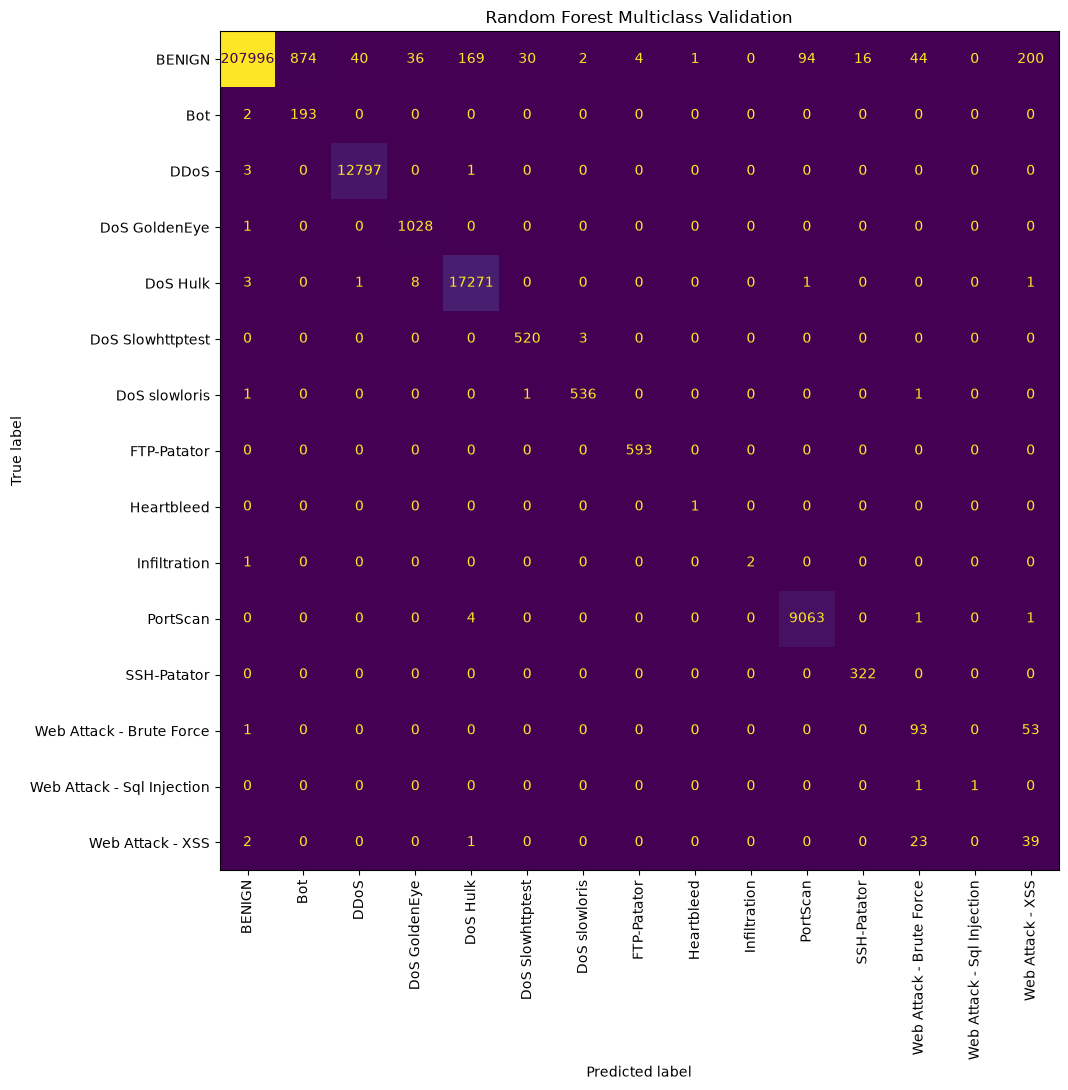

In [59]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Map the model's class names to the existing encoded IDs.
class_to_id = {
    str(class_name): class_id
    for class_id, class_name in enumerate(label_encoder.classes_)
}

# Predict class names using the existing Random Forest.
rf_val_pred_names = rf_multi.predict(X_val_multi)

# Convert predicted names into integer class IDs.
rf_val_pred = np.array(
    [class_to_id[str(name)] for name in rf_val_pred_names],
    dtype=np.int8
)

# Verify prediction and target alignment.
assert len(rf_val_pred) == len(y_val_multi)
assert np.array_equal(
    np.unique(y_val_multi),
    np.arange(15)
)
assert set(np.unique(rf_val_pred)).issubset(set(range(15)))

print("Prediction format:", rf_val_pred.dtype)
print("Validation target format:", y_val_multi.dtype)
print("Prediction-target alignment: PASS")

# Calculate metrics.
print("\nRANDOM FOREST MULTICLASS VALIDATION")
print("=" * 50)
print(f"Accuracy:          {accuracy_score(y_val_multi, rf_val_pred):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_val_multi, rf_val_pred):.4f}")
print(f"Macro F1:          {f1_score(y_val_multi, rf_val_pred, average='macro', zero_division=0):.4f}")
print(f"Weighted F1:       {f1_score(y_val_multi, rf_val_pred, average='weighted', zero_division=0):.4f}")

# Classification report.
class_ids = np.arange(15)
class_names = [str(name) for name in label_encoder.classes_]

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_val_multi,
    rf_val_pred,
    labels=class_ids,
    target_names=class_names,
    digits=4,
    zero_division=0
))

# Confusion matrix.
cm = confusion_matrix(
    y_val_multi,
    rf_val_pred,
    labels=class_ids
)

fig, ax = plt.subplots(figsize=(13, 11))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(
    ax=ax,
    xticks_rotation=90,
    values_format="d",
    colorbar=False
)

ax.set_title("Random Forest Multiclass Validation")
plt.tight_layout()
plt.show()


In [60]:

from pathlib import Path
import pandas as pd

# Reuse your existing project paths if available.
METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

rf_metrics = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_val_multi, rf_val_pred),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val_multi, rf_val_pred
    ),
    "Macro F1": f1_score(
        y_val_multi, rf_val_pred,
        average="macro", zero_division=0
    ),
    "Weighted F1": f1_score(
        y_val_multi, rf_val_pred,
        average="weighted", zero_division=0
    )
}

rf_metrics_df = pd.DataFrame([rf_metrics])

metrics_path = METRICS_DIR / "random_forest_multiclass_validation.csv"
rf_metrics_df.to_csv(metrics_path, index=False)

print(rf_metrics_df.round(5).to_string(index=False))
print("\nSaved metrics to:", metrics_path)


        Model  Accuracy  Balanced Accuracy  Macro F1  Weighted F1
Random Forest   0.99355            0.89119   0.81013      0.99512

Saved metrics to: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\outputs\metrics\random_forest_multiclass_validation.csv


In [61]:
import numpy as np

assert X_train_multi.shape == (227349, 78)
assert len(y_train_multi) == len(X_train_multi)

assert X_val_multi.shape == (252080, 78)
assert len(y_val_multi) == len(X_val_multi)

assert set(np.unique(y_train_multi)) == set(range(15))
assert set(np.unique(y_val_multi)) == set(range(15))

print("XGBoost training and validation data: READY")
print("Training:", X_train_multi.shape)
print("Validation:", X_val_multi.shape)

XGBoost training and validation data: READY
Training: (227349, 78)
Validation: (252080, 78)


In [64]:
import psutil
import gc

gc.collect()

memory = psutil.virtual_memory()

print(f"Available RAM: {memory.available / (1024**3):.2f} GB")
print(f"RAM usage: {memory.percent:.1f}%")

if memory.available < 1.5 * (1024**3):
    print("WARNING: Low available RAM. Close other applications before training.")
else:
    print("Memory check: READY")

Available RAM: 2.34 GB
RAM usage: 68.3%
Memory check: READY


In [65]:
import time
import numpy as np
import xgboost as xgb

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Verify data alignment and class encoding
assert X_train_multi.shape == (227349, 78)
assert len(X_train_multi) == len(y_train_multi)

assert X_val_multi.shape == (252080, 78)
assert len(X_val_multi) == len(y_val_multi)

assert set(np.unique(y_train_multi)) == set(range(15))
assert set(np.unique(y_val_multi)) == set(range(15))

# Ensure XGBoost receives integer class IDs
y_train_xgb = np.asarray(y_train_multi, dtype=np.int32)
y_val_xgb = np.asarray(y_val_multi, dtype=np.int32)

# Release temporary garbage before training
gc.collect()

xgb_multi = xgb.XGBClassifier(
    objective="multi:softprob",
    num_class=15,
    n_estimators=150,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="mlogloss",
    n_jobs=2,
    random_state=42
)

print("Starting XGBoost multiclass training...")
print("Training shape:", X_train_multi.shape)
print("Available RAM before training:",
      f"{psutil.virtual_memory().available / (1024**3):.2f} GB")

start_time = time.time()

xgb_multi.fit(
    X_train_multi,
    y_train_xgb,
    verbose=False
)

xgb_training_time = time.time() - start_time

print("\nXGBoost multiclass training completed.")
print(f"Training time: {xgb_training_time:.2f} seconds")
print("Available RAM after training:",
      f"{psutil.virtual_memory().available / (1024**3):.2f} GB")

Starting XGBoost multiclass training...
Training shape: (227349, 78)
Available RAM before training: 2.24 GB

XGBoost multiclass training completed.
Training time: 77.03 seconds
Available RAM after training: 2.28 GB


In [66]:
xgb_val_pred = xgb_multi.predict(X_val_multi)

assert len(xgb_val_pred) == len(y_val_xgb)
assert set(np.unique(xgb_val_pred)).issubset(set(range(15)))

xgb_accuracy = accuracy_score(y_val_xgb, xgb_val_pred)
xgb_balanced_accuracy = balanced_accuracy_score(
    y_val_xgb, xgb_val_pred
)
xgb_macro_f1 = f1_score(
    y_val_xgb, xgb_val_pred, average="macro", zero_division=0
)
xgb_weighted_f1 = f1_score(
    y_val_xgb, xgb_val_pred, average="weighted", zero_division=0
)

print("XGBOOST MULTICLASS VALIDATION")
print("=" * 55)
print(f"Accuracy:          {xgb_accuracy:.4f}")
print(f"Balanced accuracy: {xgb_balanced_accuracy:.4f}")
print(f"Macro F1:          {xgb_macro_f1:.4f}")
print(f"Weighted F1:       {xgb_weighted_f1:.4f}")
print(f"Training time:     {xgb_training_time:.2f} seconds")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_val_xgb,
    xgb_val_pred,
    labels=np.arange(15),
    target_names=list(label_encoder.classes_),
    digits=4,
    zero_division=0
))

XGBOOST MULTICLASS VALIDATION
Accuracy:          0.9984
Balanced accuracy: 0.8909
Macro F1:          0.8695
Weighted F1:       0.9985
Training time:     77.03 seconds

CLASSIFICATION REPORT
                            precision    recall  f1-score   support

                    BENIGN     1.0000    0.9985    0.9992    209506
                       Bot     0.5933    0.9949    0.7433       195
                      DDoS     0.9985    0.9999    0.9992     12801
             DoS GoldenEye     0.9913    1.0000    0.9956      1029
                  DoS Hulk     0.9975    0.9998    0.9986     17285
          DoS Slowhttptest     0.9867    0.9904    0.9885       523
             DoS slowloris     0.9871    0.9944    0.9908       539
               FTP-Patator     0.9916    1.0000    0.9958       593
                Heartbleed     0.5000    1.0000    0.6667         1
              Infiltration     1.0000    0.6667    0.8000         3
                  PortScan     0.9897    0.9994    0.9946    

In [67]:
from pathlib import Path
import joblib
import json
import numpy as np

MULTICLASS_MODEL_DIR = PROJECT_ROOT / "models" / "multiclass"
MULTICLASS_MODEL_DIR.mkdir(parents=True, exist_ok=True)

xgb_multi_path = (
    MULTICLASS_MODEL_DIR / "xgboost_multiclass_bundle.joblib"
)

xgb_multi_bundle = {
    "model": xgb_multi,
    "feature_columns": list(FEATURE_COLUMNS),
    "label_mapping": {
        int(class_id): str(label)
        for class_id, label in enumerate(label_encoder.classes_)
    },
    "model_type": "XGBClassifier",
    "task": "15-class network intrusion classification",
    "training_metrics": {
        "accuracy": float(xgb_accuracy),
        "balanced_accuracy": float(xgb_balanced_accuracy),
        "macro_f1": float(xgb_macro_f1),
        "weighted_f1": float(xgb_weighted_f1),
        "training_time_seconds": float(xgb_training_time),
    },
}

joblib.dump(xgb_multi_bundle, xgb_multi_path)

print("XGBoost multiclass bundle saved:")
print(xgb_multi_path)

# Reload and verify the artifact
loaded_bundle = joblib.load(xgb_multi_path)

assert hasattr(loaded_bundle["model"], "predict")
assert len(loaded_bundle["feature_columns"]) == 78
assert len(loaded_bundle["label_mapping"]) == 15
assert list(loaded_bundle["model"].classes_) == list(range(15))

print("\nXGBoost bundle verification: PASS")
print("Features:", len(loaded_bundle["feature_columns"]))
print("Classes:", len(loaded_bundle["label_mapping"]))

XGBoost multiclass bundle saved:
c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\models\multiclass\xgboost_multiclass_bundle.joblib

XGBoost bundle verification: PASS
Features: 78
Classes: 15


In [68]:
import pandas as pd
from pathlib import Path

comparison_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Macro F1",
        "Weighted F1",
        "Training Time (seconds)"
    ],
    "Random Forest": [
        0.99355,
        0.89119,
        0.81013,
        0.99512,
        41.21
    ],
    "XGBoost": [
        xgb_accuracy,
        xgb_balanced_accuracy,
        xgb_macro_f1,
        xgb_weighted_f1,
        xgb_training_time
    ]
})

comparison_df = comparison_df.set_index("Metric")

display(comparison_df.round(5))

METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

comparison_path = METRICS_DIR / "multiclass_validation_comparison.csv"
comparison_df.to_csv(comparison_path)

print("\nComparison saved:", comparison_path)

,Random Forest,XGBoost
Metric,,
Accuracy,0.99355,0.99842
Balanced Accuracy,0.89119,0.89091
Macro F1,0.81013,0.86952
Weighted F1,0.99512,0.99848
Training Time (seconds),41.21000,77.03049



Comparison saved: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\outputs\metrics\multiclass_validation_comparison.csv


In [69]:
print("TEST SET PREPARATION")
print("=" * 50)

print("Test indices loaded:", "test_indices" in globals())
print("Dataset path exists:", FINAL_DATA_PATH.exists())
print("Feature count:", len(FEATURE_COLUMNS))
print("Random Forest available:", "rf_multi" in globals())
print("XGBoost available:", "xgb_multi" in globals())

if "test_indices" in globals():
    print("Number of test indices:", len(test_indices))
    print("Unique test indices:", len(set(test_indices)))
    print("Test index dtype:", test_indices.dtype)

assert len(FEATURE_COLUMNS) == 78
assert "rf_multi" in globals()
assert "xgb_multi" in globals()

print("\nDiagnostic complete.")

TEST SET PREPARATION
Test indices loaded: True
Dataset path exists: True
Feature count: 78
Random Forest available: True
XGBoost available: True
Number of test indices: 252080
Unique test indices: 252080
Test index dtype: int64

Diagnostic complete.


In [70]:
import gc
import time
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# --------------------------------------------------
# 1. Verify the saved test indices
# --------------------------------------------------
test_indices = np.asarray(test_indices, dtype=np.int64)

assert len(test_indices) == 252080
assert len(np.unique(test_indices)) == len(test_indices)
assert test_indices.min() >= 0
assert test_indices.max() < pq.ParquetFile(FINAL_DATA_PATH).metadata.num_rows

# Use the same feature order as training
assert len(FEATURE_COLUMNS) == 78

test_index_set = set(test_indices.tolist())

# Store only the test features and targets, not the full dataset
X_test_parts = []
y_test_parts = []

parquet_file = pq.ParquetFile(FINAL_DATA_PATH)

# Read only the required columns, one row group at a time
for group_index in range(parquet_file.num_row_groups):
    group_start = sum(
        parquet_file.metadata.row_group(i).num_rows
        for i in range(group_index)
    )
    group_end = (
        group_start
        + parquet_file.metadata.row_group(group_index).num_rows
    )

    # Find test rows belonging to this row group
    selected_indices = [
        idx for idx in test_indices
        if group_start <= idx < group_end
    ]

    if not selected_indices:
        continue

    group_df = parquet_file.read_row_group(
        group_index,
        columns=FEATURE_COLUMNS + ["Label"]
    ).to_pandas()

    local_positions = np.asarray(
        selected_indices, dtype=np.int64
    ) - group_start

    selected_df = group_df.iloc[local_positions]

    X_test_parts.append(
        selected_df[FEATURE_COLUMNS].to_numpy(
            dtype=np.float32, copy=True
        )
    )
    y_test_parts.append(selected_df["Label"].to_numpy(copy=True))

    print(
        f"Processed row group {group_index + 1}/"
        f"{parquet_file.num_row_groups}"
    )

    del group_df, selected_df, local_positions
    gc.collect()

X_test_multi = np.concatenate(X_test_parts, axis=0)
y_test_labels = np.concatenate(y_test_parts, axis=0)

del X_test_parts, y_test_parts
gc.collect()

# Encode labels using the existing fitted encoder
y_test_multi = label_encoder.transform(y_test_labels).astype(np.int32)

# --------------------------------------------------
# 2. Verify alignment and class coverage
# --------------------------------------------------
assert X_test_multi.shape == (len(test_indices), 78)
assert len(y_test_multi) == len(X_test_multi)
assert set(np.unique(y_test_multi)) == set(range(15))

print("\nTEST DATA EXTRACTION: PASS")
print("Test feature shape:", X_test_multi.shape)
print("Test target shape:", y_test_multi.shape)
print("Feature dtype:", X_test_multi.dtype)
print("Classes represented:", len(np.unique(y_test_multi)))

Processed row group 1/3
Processed row group 2/3
Processed row group 3/3

TEST DATA EXTRACTION: PASS
Test feature shape: (252080, 78)
Test target shape: (252080,)
Feature dtype: float32
Classes represented: 15


In [74]:

import numpy as np
import pandas as pd
import time

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ==================================================
# 1. VALIDATE TEST DATA
# ==================================================

assert X_test_multi.shape == (252080, 78), (
    f"Unexpected test feature shape: {X_test_multi.shape}"
)

assert len(X_test_multi) == len(y_test_multi), (
    "Test features and targets have different lengths."
)

assert np.isfinite(X_test_multi).all(), (
    "Test features contain NaN or infinite values."
)

assert set(np.unique(y_test_multi)) == set(range(15)), (
    "Test targets must contain encoded class IDs 0 to 14."
)

# Confirm both models use the expected feature order.
assert list(rf_multi_bundle["feature_columns"]) == list(FEATURE_COLUMNS)
assert list(xgb_multi_bundle["feature_columns"]) == list(FEATURE_COLUMNS)

# ==================================================
# 2. EVALUATE BOTH MODELS
# ==================================================

models = {
    "Random Forest": rf_multi_bundle["model"],
    "XGBoost": xgb_multi_bundle["model"]
}

results = []
test_predictions = {}

for model_name, model in models.items():
    print(f"\nEvaluating {model_name}...")

    start = time.time()
    raw_predictions = np.asarray(model.predict(X_test_multi))
    elapsed = time.time() - start

    # Convert predictions to the same integer IDs as y_test_multi.
    model_classes = np.asarray(model.classes_)

    if np.issubdtype(model_classes.dtype, np.number):
        # XGBoost already predicts encoded class IDs.
        predictions_encoded = raw_predictions.astype(np.int64)

    else:
        # Random Forest predicts class-name strings.
        predictions_encoded = np.asarray(
            [label_to_id[str(label)] for label in raw_predictions],
            dtype=np.int64
        )

    # Verify prediction-target alignment.
    assert len(predictions_encoded) == len(y_test_multi), (
        f"{model_name}: prediction count mismatch."
    )

    assert set(np.unique(predictions_encoded)).issubset(set(range(15))), (
        f"{model_name}: invalid predicted class IDs."
    )

    test_predictions[model_name] = predictions_encoded

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_test_multi, predictions_encoded
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test_multi, predictions_encoded
        ),
        "Macro F1": f1_score(
            y_test_multi,
            predictions_encoded,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test_multi,
            predictions_encoded,
            average="weighted",
            zero_division=0
        ),
        "Test Prediction Time (seconds)": elapsed
    })

    print(f"{model_name}: prediction alignment PASS")
    print(f"Prediction format: {predictions_encoded.dtype}")
    print(f"Prediction shape: {predictions_encoded.shape}")
    print(f"Test target shape: {y_test_multi.shape}")

# ==================================================
# 3. DISPLAY TEST METRICS
# ==================================================

test_comparison = pd.DataFrame(results).set_index("Model")

print("\nFINAL MULTICLASS TEST COMPARISON")
print("=" * 65)
display(test_comparison.round(5))



Evaluating Random Forest...
Random Forest: prediction alignment PASS
Prediction format: int64
Prediction shape: (252080,)
Test target shape: (252080,)

Evaluating XGBoost...
XGBoost: prediction alignment PASS
Prediction format: int64
Prediction shape: (252080,)
Test target shape: (252080,)

FINAL MULTICLASS TEST COMPARISON


,Accuracy,Balanced Accuracy,Macro F1,Weighted F1,Test Prediction Time (seconds)
Model,,,,,
Random Forest,0.99387,0.91845,0.85081,0.99532,3.12143
XGBoost,0.99856,0.91252,0.90825,0.99859,5.25232


In [72]:
import numpy as np

print("Prediction data type:", np.asarray(predictions).dtype)
print("First 10 predictions:", np.asarray(predictions)[:10])
print("Model classes:", model.classes_)
print("Label encoder classes:", label_encoder.classes_)

Prediction data type: object
First 10 predictions: ['DDoS' 'BENIGN' 'PortScan' 'BENIGN' 'DDoS' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'BENIGN']
Model classes: ['BENIGN' 'Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'Heartbleed' 'Infiltration' 'PortScan'
 'SSH-Patator' 'Web Attack - Brute Force' 'Web Attack - Sql Injection'
 'Web Attack - XSS']
Label encoder classes: ['BENIGN' 'Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'Heartbleed' 'Infiltration' 'PortScan'
 'SSH-Patator' 'Web Attack - Brute Force' 'Web Attack - Sql Injection'
 'Web Attack - XSS']


In [73]:
# Convert predicted label strings into encoded class IDs
predictions_encoded = label_encoder.transform(
    np.asarray(predictions).astype(str)
)

# Verify alignment before evaluation
assert len(predictions_encoded) == len(y_test_multi), (
    "Prediction count does not match test target count."
)

assert set(np.unique(predictions_encoded)).issubset(set(range(15))), (
    "Unexpected encoded class IDs detected."
)

assert set(np.unique(y_test_multi)).issubset(set(range(15))), (
    "Test targets contain invalid class IDs."
)

test_predictions[model_name] = predictions_encoded

print(f"{model_name}: test prediction validation PASS")
print("Prediction shape:", predictions_encoded.shape)
print("Target shape:", y_test_multi.shape)

Random Forest: test prediction validation PASS
Prediction shape: (252080,)
Target shape: (252080,)


In [75]:

from pathlib import Path

METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

comparison_path = METRICS_DIR / "multiclass_test_comparison.csv"

test_comparison.to_csv(comparison_path)

print("Test comparison saved:")
print(comparison_path)

assert comparison_path.exists()
assert len(test_comparison) == 2

print("Metric export verification: PASS")


Test comparison saved:
c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\outputs\metrics\multiclass_test_comparison.csv
Metric export verification: PASS


In [77]:

import numpy as np
import pandas as pd
from sklearn.metrics import classification_report

# Reverse the existing mapping: class ID -> class name
id_to_label = {
    int(class_id): str(label)
    for label, class_id in label_to_id.items()
}

# Validate the mapping
assert len(id_to_label) == 15
assert set(id_to_label.keys()) == set(range(15))

print("CLASS MAPPING VALIDATION")
for class_id in range(15):
    print(f"{class_id} -> {id_to_label[class_id]}")

print("\nMapping validation: PASS")

# Generate test classification reports
reports = {}

for model_name, predictions in test_predictions.items():
    predictions = np.asarray(predictions)

    assert len(predictions) == len(y_test_multi), (
        f"{model_name}: prediction and target lengths differ."
    )

    report = classification_report(
        y_test_multi,
        predictions,
        labels=list(range(15)),
        target_names=[id_to_label[i] for i in range(15)],
        output_dict=True,
        zero_division=0
    )

    reports[model_name] = report

    print(f"\n{model_name.upper()} TEST CLASSIFICATION REPORT")
    display(pd.DataFrame(report).transpose().round(4))

print("\nClassification reports generated successfully.")


CLASS MAPPING VALIDATION
0 -> BENIGN
1 -> Bot
2 -> DDoS
3 -> DoS GoldenEye
4 -> DoS Hulk
5 -> DoS Slowhttptest
6 -> DoS slowloris
7 -> FTP-Patator
8 -> Heartbleed
9 -> Infiltration
10 -> PortScan
11 -> SSH-Patator
12 -> Web Attack - Brute Force
13 -> Web Attack - Sql Injection
14 -> Web Attack - XSS

Mapping validation: PASS

RANDOM FOREST TEST CLASSIFICATION REPORT


,precision,recall,f1-score,support
BENIGN,1.0000,0.9931,0.9965,209506.0000
Bot,0.1851,0.9846,0.3117,195.0000
DDoS,0.9971,0.9996,0.9984,12801.0000
DoS GoldenEye,0.9599,0.9990,0.9790,1029.0000
DoS Hulk,0.9907,0.9991,0.9949,17285.0000
DoS Slowhttptest,0.9270,0.9962,0.9604,523.0000
DoS slowloris,0.9907,0.9926,0.9916,538.0000
FTP-Patator,0.9983,0.9983,0.9983,593.0000
Heartbleed,1.0000,1.0000,1.0000,1.0000
Infiltration,1.0000,1.0000,1.0000,4.0000



XGBOOST TEST CLASSIFICATION REPORT


,precision,recall,f1-score,support
BENIGN,1.0000,0.9986,0.9993,209506.0000
Bot,0.6576,0.9949,0.7918,195.0000
DDoS,0.9984,1.0000,0.9992,12801.0000
DoS GoldenEye,0.9885,1.0000,0.9942,1029.0000
DoS Hulk,0.9979,0.9998,0.9988,17285.0000
DoS Slowhttptest,0.9757,0.9962,0.9858,523.0000
DoS slowloris,0.9944,0.9944,0.9944,538.0000
FTP-Patator,0.9966,0.9983,0.9975,593.0000
Heartbleed,1.0000,1.0000,1.0000,1.0000
Infiltration,1.0000,1.0000,1.0000,4.0000



Classification reports generated successfully.


In [78]:

# Save classification reports
for model_name, report in reports.items():
    safe_name = model_name.lower().replace(" ", "_")

    report_path = (
        METRICS_DIR /
        f"{safe_name}_test_classification_report.csv"
    )

    pd.DataFrame(report).transpose().to_csv(report_path)

    print(f"Saved: {report_path}")

print("\nClassification report export: PASS")


Saved: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\outputs\metrics\random_forest_test_classification_report.csv
Saved: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\outputs\metrics\xgboost_test_classification_report.csv

Classification report export: PASS


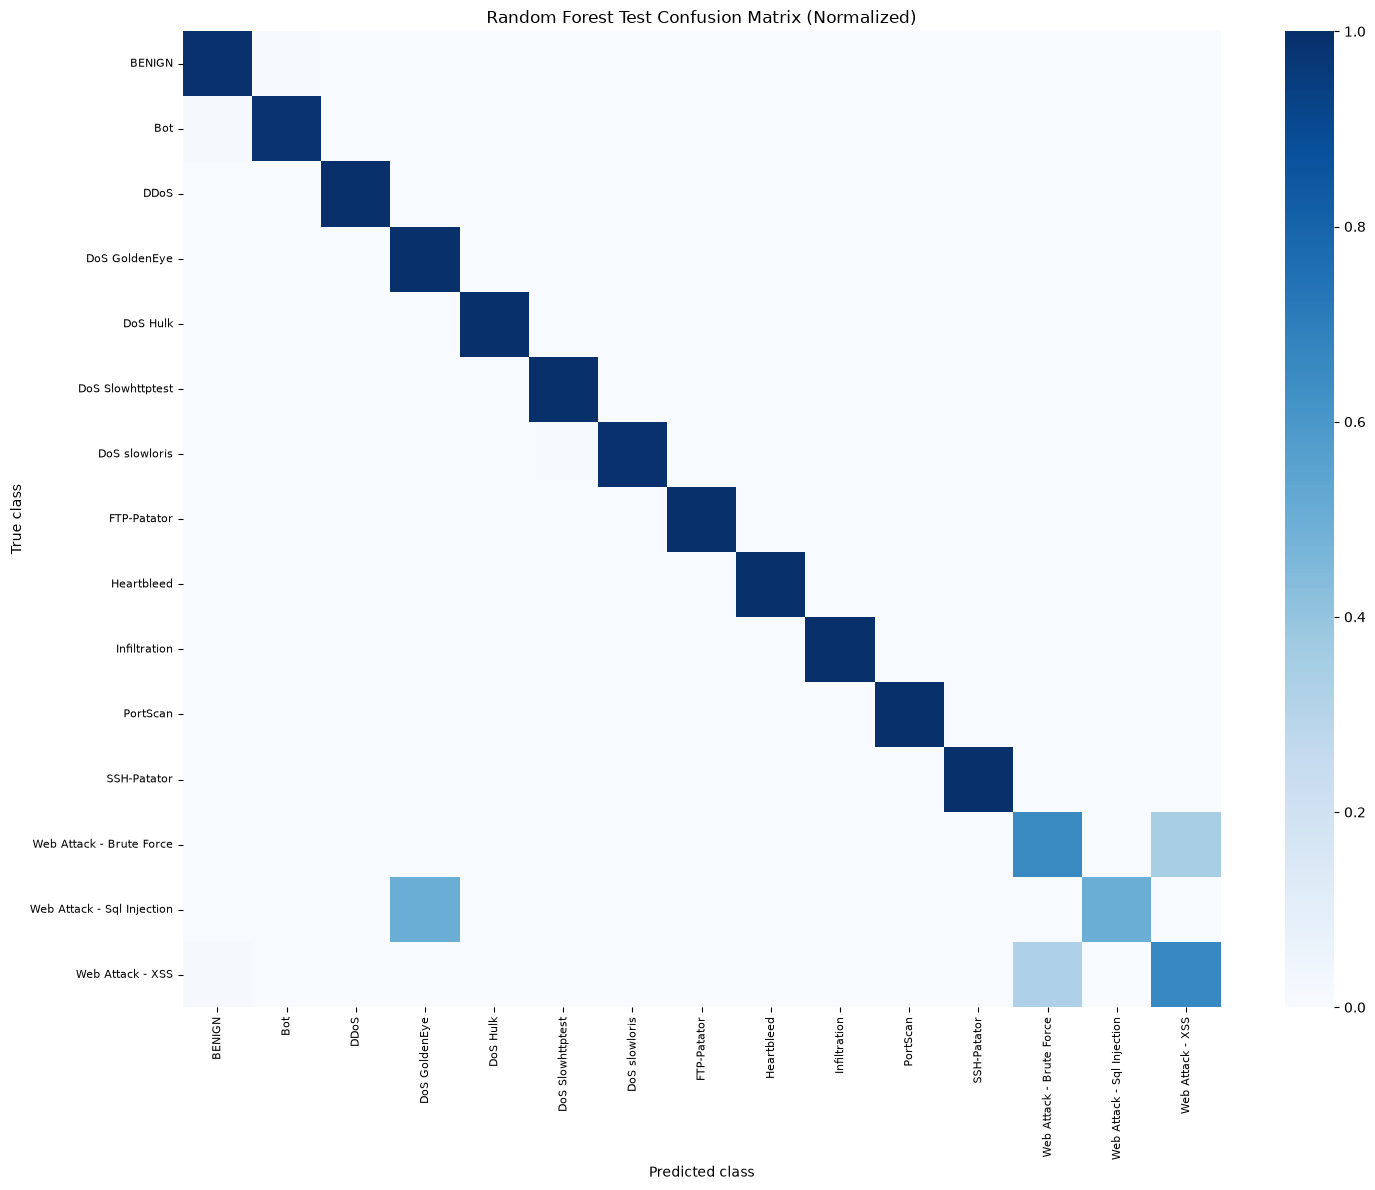

Confusion matrix CSV saved: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\outputs\metrics\random_forest_test_confusion_matrix.csv
Confusion matrix figure saved: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\outputs\figures\random_forest_test_confusion_matrix.png


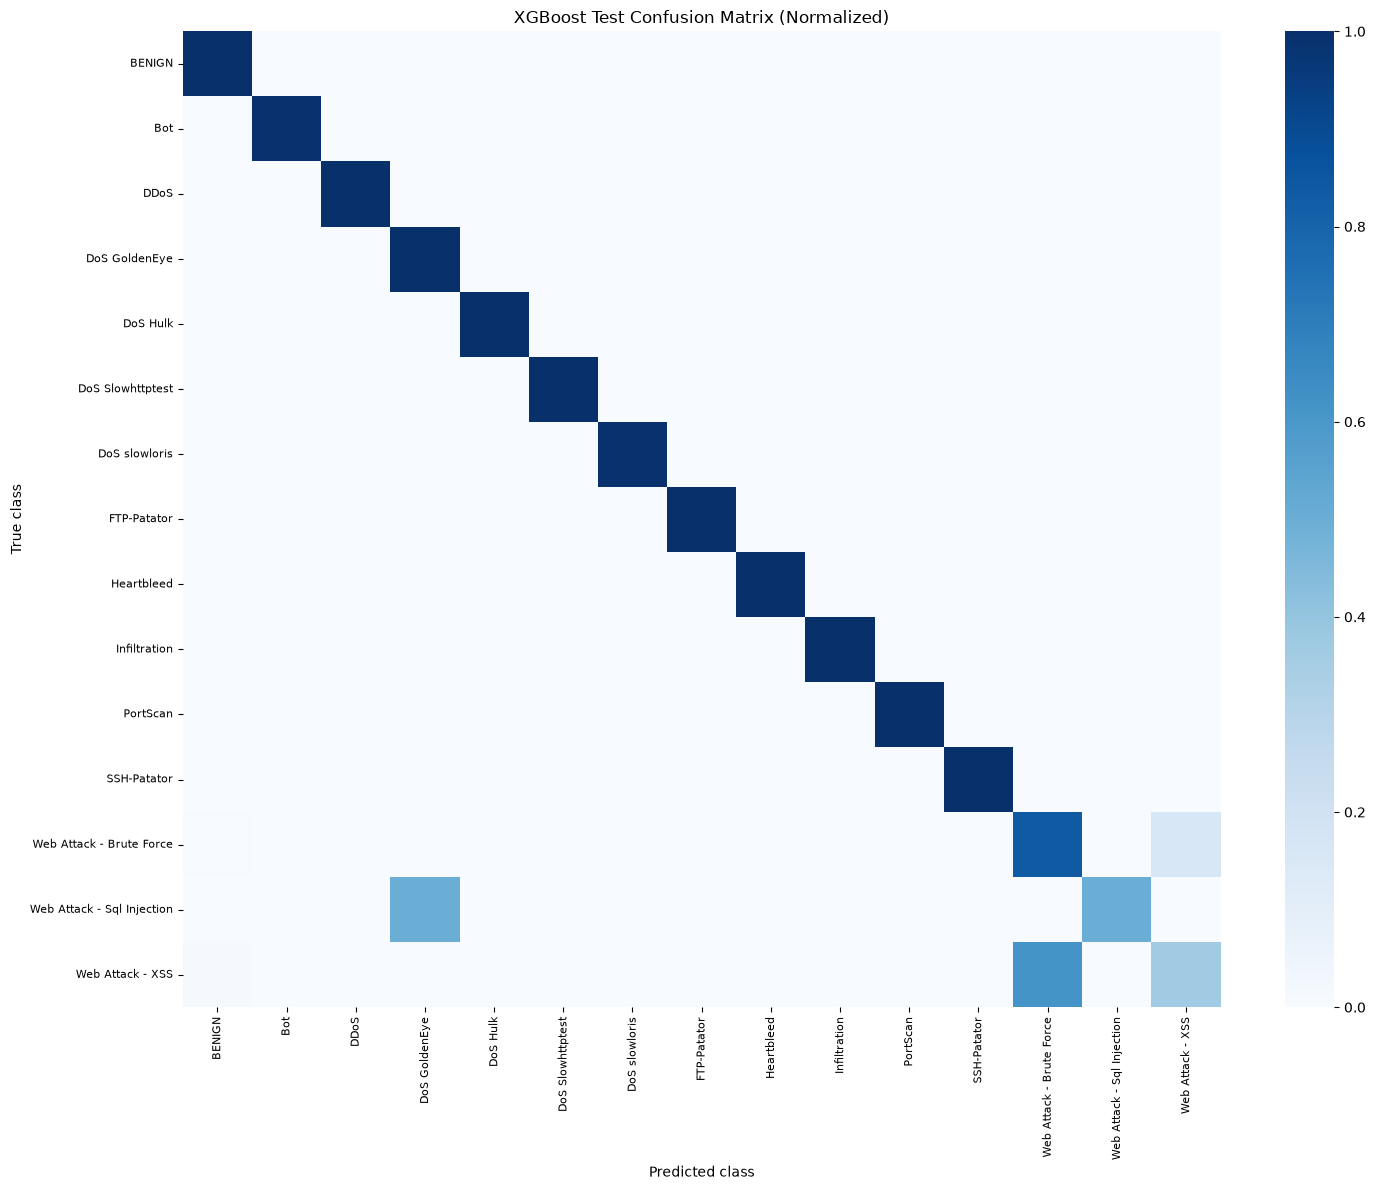

Confusion matrix CSV saved: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\outputs\metrics\xgboost_test_confusion_matrix.csv
Confusion matrix figure saved: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\outputs\figures\xgboost_test_confusion_matrix.png

Confusion matrix generation: PASS


In [80]:

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

class_ids = list(range(15))
class_names = [id_to_label[i] for i in class_ids]

for model_name, predictions in test_predictions.items():

    cm = confusion_matrix(
        y_test_multi,
        predictions,
        labels=class_ids
    )

    # Save the raw confusion matrix values
    cm_df = pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    )

    safe_name = model_name.lower().replace(" ", "_")

    cm_path = METRICS_DIR / f"{safe_name}_test_confusion_matrix.csv"
    cm_df.to_csv(cm_path)

    # Plot row-normalized values to compare classes of different sizes
    row_totals = cm.sum(axis=1, keepdims=True)
    cm_normalized = np.divide(
        cm,
        row_totals,
        out=np.zeros_like(cm, dtype=float),
        where=row_totals != 0
    )

    plt.figure(figsize=(15, 12))

    sns.heatmap(
        cm_normalized,
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        vmin=0,
        vmax=1
    )

    plt.title(f"{model_name} Test Confusion Matrix (Normalized)")
    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    plt.xticks(rotation=90, fontsize=8)
    plt.yticks(rotation=0, fontsize=8)
    plt.tight_layout()

    figure_path = FIGURES_DIR / f"{safe_name}_test_confusion_matrix.png"
    plt.savefig(figure_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

    print(f"Confusion matrix CSV saved: {cm_path}")
    print(f"Confusion matrix figure saved: {figure_path}")

print("\nConfusion matrix generation: PASS")
